In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
data = pd.read_csv("../data/tcs_stock_data.csv")
data.head()

,Price,Adj Close,Close,High,Low,Open,Volume
0,Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
1,Date,NaN,NaN,NaN,NaN,NaN,NaN
2,2018-01-01,1063.442138671875,1322.800048828125,1347.4000244140625,1317.5,1341.1500244140625,1351760
3,2018-01-02,1057.6541748046875,1315.5999755859375,1334.800048828125,1310.0999755859375,1330.0,1920290
4,2018-01-03,1060.6488037109375,1319.324951171875,1334.5,1315.5999755859375,1316.0,1257120


In [4]:

import pandas as pd

# Reload the CSV, skipping the two extra header rows
data = pd.read_csv(
    "../data/tcs_stock_data.csv",
    skiprows=[1, 2]
)

# Rename the first column to Date
data.rename(columns={"Price": "Date"}, inplace=True)

# Convert Date to datetime format
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Convert price and volume columns to numeric values
for col in ["Adj Close", "Close", "High", "Low", "Open", "Volume"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove rows without a valid date
data = data.dropna(subset=["Date"])

# Sort by date
data = data.sort_values("Date").reset_index(drop=True)

print("Dataset cleaned successfully!")
print("Dataset shape:", data.shape)
display(data.head())
print(data.dtypes)


Dataset cleaned successfully!
Dataset shape: (2165, 7)


,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,1063.442139,1322.800049,1347.400024,1317.500000,1341.150024,1351760
1,2018-01-02,1057.654175,1315.599976,1334.800049,1310.099976,1330.000000,1920290
2,2018-01-03,1060.648804,1319.324951,1334.500000,1315.599976,1316.000000,1257120
3,2018-01-04,1068.064941,1328.550049,1331.000000,1320.000000,1325.000000,913082
4,2018-01-05,1080.968262,1344.599976,1349.750000,1325.000000,1325.000000,1153706


Date         datetime64[us]
Adj Close           float64
Close               float64
High                float64
Low                 float64
Open                float64
Volume                int64
dtype: object


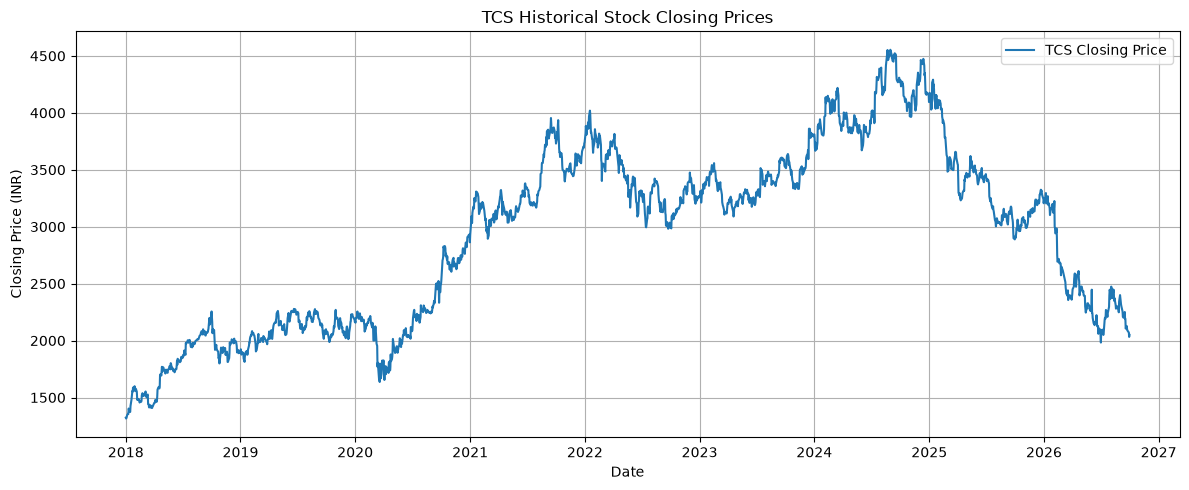

In [5]:

plt.figure(figsize=(12, 5))

plt.plot(data["Date"], data["Close"], label="TCS Closing Price")

plt.title("TCS Historical Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:

# Check missing values in each column
print("Missing values:")
print(data.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", data.duplicated().sum())

# Summary statistics
print("\nStatistical summary:")
display(data.describe())


Missing values:
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Duplicate rows: 0

Statistical summary:


,Date,Adj Close,Close,High,Low,Open,Volume
count,2165,2165.000000,2165.000000,2165.000000,2165.000000,2165.000000,2.165000e+03
mean,2022-05-21 14:11:21.755196,2620.151454,2927.491476,2956.991497,2899.657617,2929.200959,2.930600e+06
min,2018-01-01 00:00:00,1057.654175,1315.599976,1331.000000,1310.099976,1316.000000,0.000000e+00
25%,2020-03-17 00:00:00,1836.427368,2167.600098,2190.949951,2146.699951,2172.000000,1.785879e+06
50%,2022-05-23 00:00:00,2816.089111,3132.000000,3156.850098,3106.000000,3135.000000,2.460591e+06
75%,2024-08-01 00:00:00,3163.038574,3493.050049,3524.000000,3464.300049,3492.000000,3.402251e+06
max,2026-09-30 00:00:00,4230.709961,4553.750000,4592.250000,4512.000000,4576.000000,8.806715e+07
std,NaN,775.546241,782.192838,786.830450,777.853488,782.287198,2.598907e+06


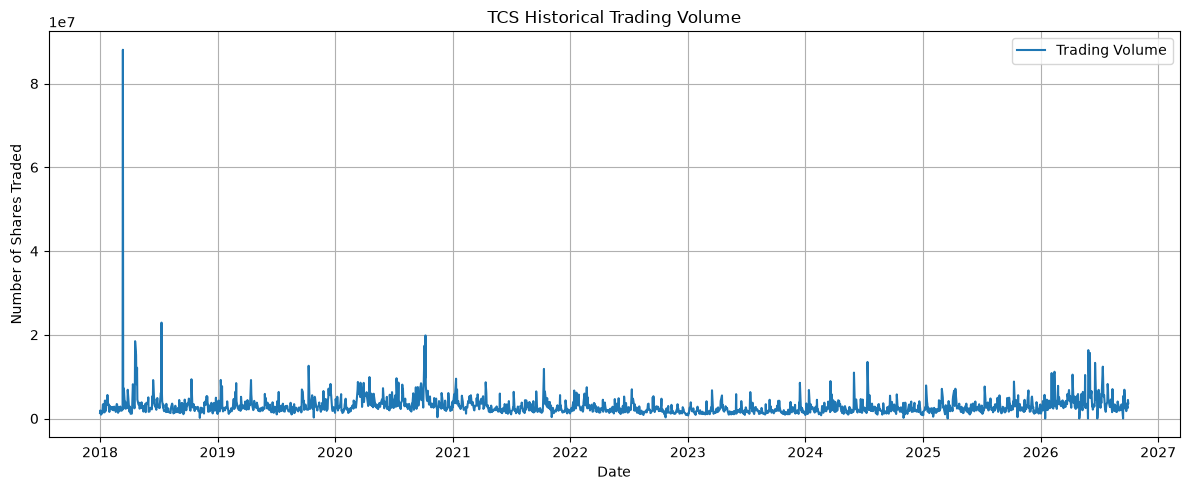

In [7]:

plt.figure(figsize=(12, 5))

plt.plot(data["Date"], data["Volume"], label="Trading Volume")

plt.title("TCS Historical Trading Volume")
plt.xlabel("Date")
plt.ylabel("Number of Shares Traded")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


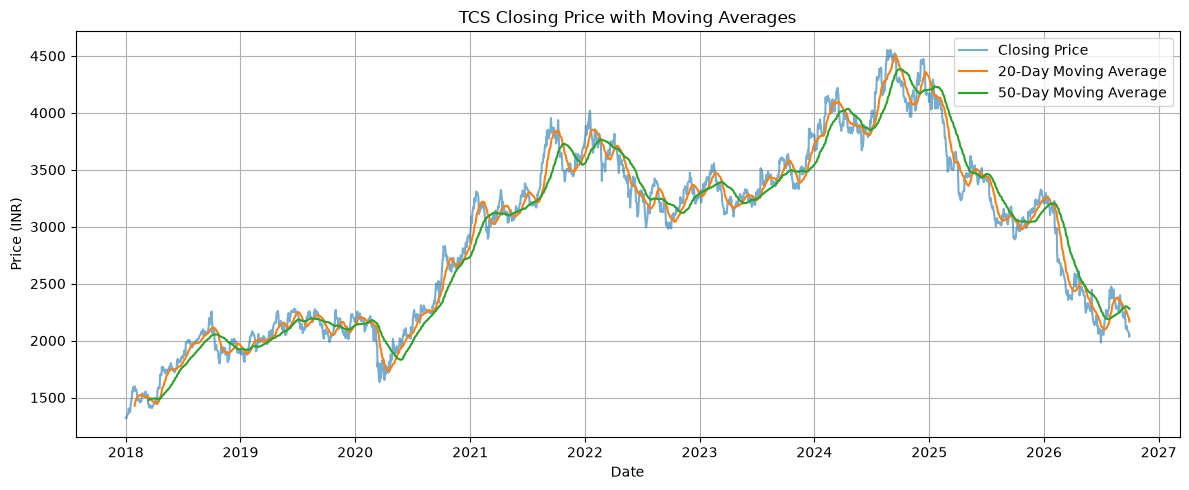

In [8]:

# Calculate moving averages
data["MA_20"] = data["Close"].rolling(window=20).mean()
data["MA_50"] = data["Close"].rolling(window=50).mean()

plt.figure(figsize=(12, 5))

plt.plot(data["Date"], data["Close"], label="Closing Price", alpha=0.6)
plt.plot(data["Date"], data["MA_20"], label="20-Day Moving Average")
plt.plot(data["Date"], data["MA_50"], label="50-Day Moving Average")

plt.title("TCS Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [9]:

print("Missing values in each column:")
print(data.isnull().sum())

print("\nDuplicate rows:")
print(data.duplicated().sum())

print("\nDataset statistics:")
display(data.describe())


Missing values in each column:
Date          0
Adj Close     0
Close         0
High          0
Low           0
Open          0
Volume        0
MA_20        19
MA_50        49
dtype: int64

Duplicate rows:
0

Dataset statistics:


,Date,Adj Close,Close,High,Low,Open,Volume,MA_20,MA_50
count,2165,2165.000000,2165.000000,2165.000000,2165.000000,2165.000000,2.165000e+03,2146.000000,2116.000000
mean,2022-05-21 14:11:21.755196,2620.151454,2927.491476,2956.991497,2899.657617,2929.200959,2.930600e+06,2937.954924,2952.761423
min,2018-01-01 00:00:00,1057.654175,1315.599976,1331.000000,1310.099976,1316.000000,0.000000e+00,1428.372510,1476.552009
25%,2020-03-17 00:00:00,1836.427368,2167.600098,2190.949951,2146.699951,2172.000000,1.785879e+06,2159.344994,2170.016252
50%,2022-05-23 00:00:00,2816.089111,3132.000000,3156.850098,3106.000000,3135.000000,2.460591e+06,3148.858752,3153.185496
75%,2024-08-01 00:00:00,3163.038574,3493.050049,3524.000000,3464.300049,3492.000000,3.402251e+06,3490.856232,3492.585004
max,2026-09-30 00:00:00,4230.709961,4553.750000,4592.250000,4512.000000,4576.000000,8.806715e+07,4502.377490,4382.910986
std,NaN,775.546241,782.192838,786.830450,777.853488,782.287198,2.598907e+06,772.924128,760.865166


In [10]:

# Create a separate dataset for modelling
model_data = data.copy()

# Target: next available trading observation's closing price
model_data["Target"] = model_data["Close"].shift(-1)

# Remove the last row because it has no next closing price
model_data = model_data.dropna(subset=["Target"]).copy()

# Features used to predict the next closing price
features = ["Open", "High", "Low", "Close", "Volume"]

X = model_data[features]
y = model_data["Target"]

print("Features:", features)
print("Number of samples:", len(model_data))
print("\nFirst five target values:")
display(model_data[["Date", "Close", "Target"]].head())


Features: ['Open', 'High', 'Low', 'Close', 'Volume']
Number of samples: 2164

First five target values:


,Date,Close,Target
0,2018-01-01,1322.800049,1315.599976
1,2018-01-02,1315.599976,1319.324951
2,2018-01-03,1319.324951,1328.550049
3,2018-01-04,1328.550049,1344.599976
4,2018-01-05,1344.599976,1357.199951


In [11]:

from sklearn.model_selection import train_test_split

# Keep the time order; do not shuffle
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", model_data["Date"].iloc[0],
      "to", model_data["Date"].iloc[split_index - 1])
print("Testing period:", model_data["Date"].iloc[split_index],
      "to", model_data["Date"].iloc[-1])


Training samples: 1731
Testing samples: 433
Training period: 2018-01-01 00:00:00 to 2025-01-06 00:00:00
Testing period: 2025-01-07 00:00:00 to 2026-09-29 00:00:00


In [12]:

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [13]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae:.2f} INR")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} INR")
print(f"R² Score: {r2:.4f}")


Mean Absolute Error (MAE): 38.75 INR
Root Mean Squared Error (RMSE): 52.38 INR
R² Score: 0.9914


In [14]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Baseline: predict the next close using the current close
baseline_predictions = X_test["Close"].to_numpy()

results = pd.DataFrame({
    "Model": ["Previous Close Baseline", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, predictions))
    ],
    "R2 Score": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, predictions)
    ]
})

display(results.round(4))


,Model,MAE,RMSE,R2 Score
0,Previous Close Baseline,32.3538,45.9445,0.9934
1,Random Forest,38.7518,52.3751,0.9914


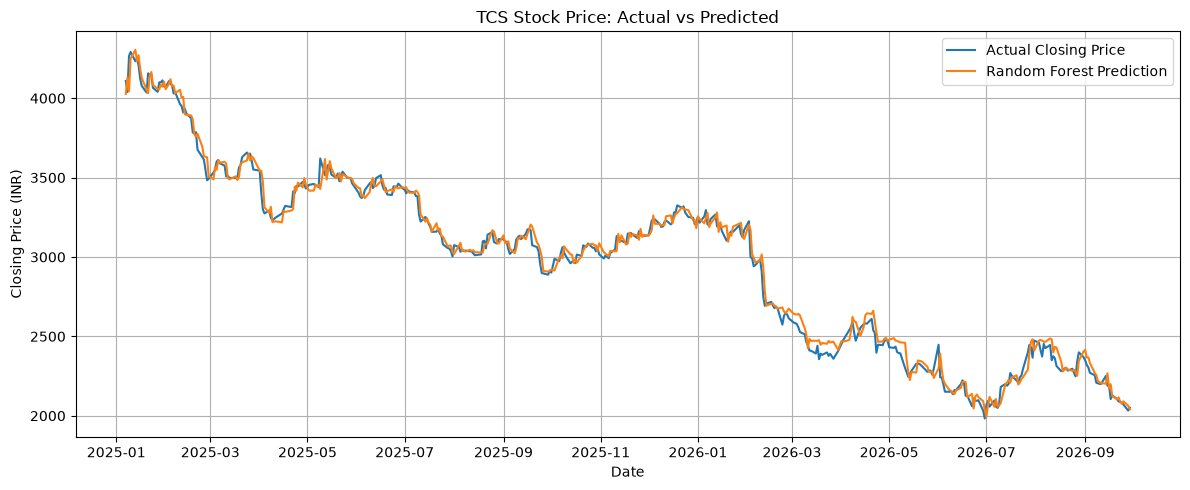

In [15]:

plt.figure(figsize=(12, 5))

plt.plot(
    model_data["Date"].iloc[split_index:],
    y_test.to_numpy(),
    label="Actual Closing Price"
)

plt.plot(
    model_data["Date"].iloc[split_index:],
    predictions,
    label="Random Forest Prediction"
)

plt.title("TCS Stock Price: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Closing Price (INR)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


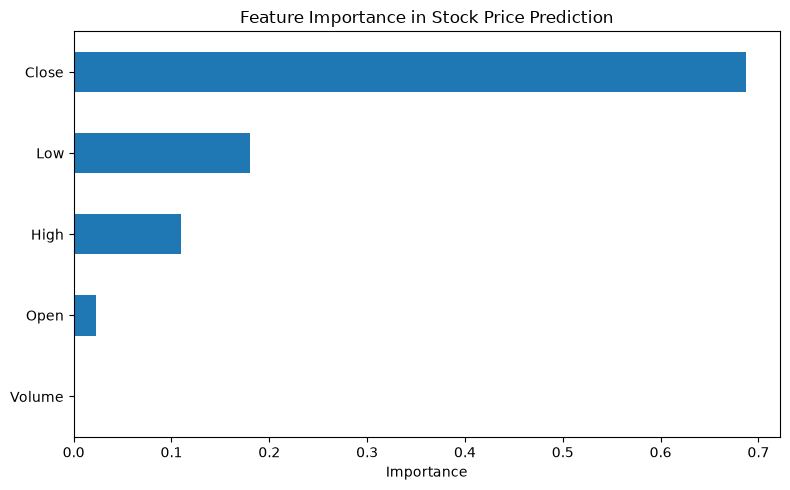

In [16]:

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))

plt.title("Feature Importance in Stock Price Prediction")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [17]:

import joblib
from pathlib import Path

project_folder = Path.cwd().parent
model_folder = project_folder / "models"
model_folder.mkdir(parents=True, exist_ok=True)

model_path = model_folder / "random_forest_stock_model.pkl"

joblib.dump(model, model_path)

print("Model saved successfully at:")
print(model_path.resolve())


Model saved successfully at:
C:\Users\sanjana.v\Downloads\Stock price prediction\models\random_forest_stock_model.pkl


In [18]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Random Forest model evaluation
rf_mae = mean_absolute_error(y_test, predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, predictions))

# Baseline: predict tomorrow's close as today's close
baseline_predictions = X_test["Close"].to_numpy()

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

results = pd.DataFrame({
    "Model": ["Random Forest", "Previous Close Baseline"],
    "MAE": [rf_mae, baseline_mae],
    "RMSE": [rf_rmse, baseline_rmse],
})

display(results.round(2))

if rf_mae < baseline_mae:
    print("Random Forest has lower MAE than the baseline.")
else:
    print("Random Forest does not beat the baseline on MAE.")


,Model,MAE,RMSE
0,Random Forest,38.75,52.38
1,Previous Close Baseline,32.35,45.94


Random Forest does not beat the baseline on MAE.


In [19]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Start with the cleaned historical dataset
improved_data = data.sort_values("Date").copy()
improved_data = improved_data.reset_index(drop=True)

# Features based only on information available up to the current day
improved_data["Return_1d"] = improved_data["Close"].pct_change()
improved_data["Return_5d"] = improved_data["Close"].pct_change(5)
improved_data["MA_5"] = improved_data["Close"].rolling(5).mean()
improved_data["MA_20"] = improved_data["Close"].rolling(20).mean()
improved_data["Volume_Change"] = improved_data["Volume"].pct_change()

# Target: next available trading day's closing price
improved_data["Target"] = improved_data["Close"].shift(-1)

features = [
    "Open", "High", "Low", "Close", "Volume",
    "Return_1d", "Return_5d", "MA_5", "MA_20",
    "Volume_Change"
]

improved_data = improved_data.replace([np.inf, -np.inf], np.nan)
improved_data = improved_data.dropna(
    subset=features + ["Target"]
).copy()

X_new = improved_data[features]
y_new = improved_data["Target"]

# Preserve chronological order: no random shuffling
split = int(len(improved_data) * 0.8)

X_train_new = X_new.iloc[:split]
X_test_new = X_new.iloc[split:]
y_train_new = y_new.iloc[:split]
y_test_new = y_new.iloc[split:]

# Train the improved Random Forest model
improved_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

improved_model.fit(X_train_new, y_train_new)
improved_predictions = improved_model.predict(X_test_new)

# Compare against predicting that tomorrow's close equals today's close
baseline_predictions = X_test_new["Close"].to_numpy()

results = pd.DataFrame({
    "Model": ["Improved Random Forest", "Previous-close baseline"],
    "MAE": [
        mean_absolute_error(y_test_new, improved_predictions),
        mean_absolute_error(y_test_new, baseline_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_new, improved_predictions)),
        np.sqrt(mean_squared_error(y_test_new, baseline_predictions))
    ]
})

display(results.round(2))


,Model,MAE,RMSE
0,Improved Random Forest,43.95,58.50
1,Previous-close baseline,32.23,45.92


In [20]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Linear Regression using the same chronological split
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train_new, y_train_new)
linear_predictions = linear_model.predict(X_test_new)

baseline_predictions = X_test_new["Close"].to_numpy()

comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Improved Random Forest",
        "Linear Regression",
        "Previous-close baseline"
    ],
    "MAE": [
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test_new, improved_predictions),
        mean_absolute_error(y_test_new, linear_predictions),
        mean_absolute_error(y_test_new, baseline_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, predictions)),
        np.sqrt(mean_squared_error(y_test_new, improved_predictions)),
        np.sqrt(mean_squared_error(y_test_new, linear_predictions)),
        np.sqrt(mean_squared_error(y_test_new, baseline_predictions))
    ]
})

display(comparison.round(2))


,Model,MAE,RMSE
0,Original Random Forest,38.75,52.38
1,Improved Random Forest,43.95,58.50
2,Linear Regression,32.71,46.24
3,Previous-close baseline,32.23,45.92


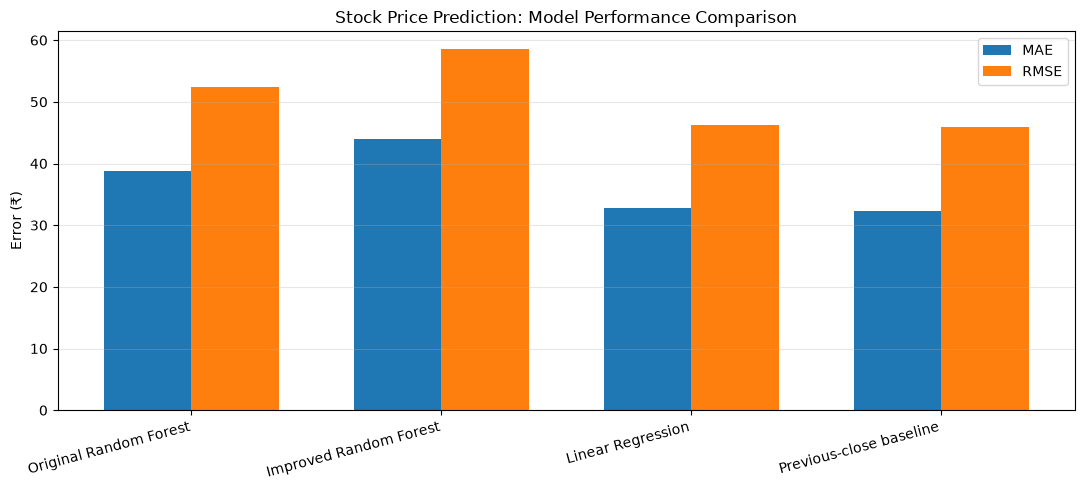

In [22]:

import matplotlib.pyplot as plt
import numpy as np

models = comparison["Model"].tolist()
mae_values = comparison["MAE"].tolist()
rmse_values = comparison["RMSE"].tolist()

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(x - width / 2, mae_values, width, label="MAE")
ax.bar(x + width / 2, rmse_values, width, label="RMSE")

ax.set_title("Stock Price Prediction: Model Performance Comparison")
ax.set_ylabel("Error (₹)")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()
